# Monte Carlo & Synthetic Options Pricing

## Dispersion payoff equation

Basket variance dispersion payoff over horizon $[t, t+\Delta]$:

$$D_t = \sum_{i=1}^{21} w_i^{\text{SX5E}} RV_i(t, t+\Delta) - RV_{\text{SX5E}}(t, t+\Delta)$$

where realised variance is:

$$RV_i(t, t+\Delta) = 252 \int_t^{t+\Delta} \sigma_i^2(s) ds \approx 252 \sum_{j=1}^{n} r_{i,j}^2$$

Fair value under risk-neutral measure:

$$y_t = \mathbb{E}_t^Q \left[ D_t \mid \mathcal{F}_t \right] = \mathbb{E}_t^Q \left[ \sum_{i=1}^{21} w_i RV_i - RV_{\text{index}} \right]$$

Estimated via Monte Carlo with 50,000 paths under Geometric Brownian Motion + synthetic IV surfaces.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (13, 6)

project_root = Path.cwd().parent
data_dir = project_root / 'output' / 'datasets'

## Load Monte Carlo targets

50k paths from `src/labels/monte_carlo_simulator.py`. Geometric Brownian motion with historical correlation structure from `returns.parquet`.

In [4]:
y_train = np.load(data_dir / 'labels' / 'y_train.npy')
y_val = np.load(data_dir / 'labels' / 'y_val.npy')
y_test = np.load(data_dir / 'labels' / 'y_test.npy')

print(f"Train: {len(y_train)}, Val: {len(y_val)}, Test: {len(y_test)}")
print(f"\nTrain stats: mean={y_train.mean():.1f}bps, std={y_train.std():.0f}bps")
print(f"Val:   mean={y_val.mean():.1f}bps, std={y_val.std():.0f}bps")
print(f"Test:  mean={y_test.mean():.1f}bps, std={y_test.std():.0f}bps")

Train: 1448, Val: 180, Test: 298

Train stats: mean=-62.1bps, std=32bps
Val:   mean=-58.5bps, std=29bps
Test:  mean=-87.5bps, std=21bps


## Synthetic IV surfaces

Parametrized via SVI + Heston term structure. 7 moneyness strikes: $\sigma(K,t)$ for $K \in \{-20,-10,-5,\text{ATM},+5,+10,+20\}$ bps per asset (7 × 21) = 147D block

Captures smile/skew/term dynamics.

In [16]:
X_train = np.load(data_dir / 'features' / 'X_train.npy')
X_val = np.load(data_dir / 'features' / 'X_val.npy')
X_test = np.load(data_dir / 'features' / 'X_test.npy')

print(f"Feature shapes: Train {X_train.shape}, Val {X_val.shape}, Test {X_test.shape}")

iv_block_idx = slice(84, 231)
iv_train = X_train[:, iv_block_idx]
print(f"\nIV surface: {iv_train.shape} (samples, 21×7)")
print(f"Mean IV (standardised): {iv_train.mean():.3f}, Std: {iv_train.std():.3f}")

Feature shapes: Train (1448, 274), Val (180, 274), Test (298, 274)

IV surface: (1448, 147) (samples, 21×7)
Mean IV (standardised): 0.000, Std: 1.000


## Feature blocks: spots, forwards, rates, yields

42D each. Cost-of-carry embedded (forward prices for 21 assets).

In [6]:
spot_fwd_idx = slice(0, 42)
rates_idx = slice(42, 84)

sf = X_train[:, spot_fwd_idx]
rty = X_train[:, rates_idx]

print(f"Spot/Forward block: {sf.shape}, mean={sf.mean():.3f}")
print(f"Rates/Yields block: {rty.shape}, mean={rty.mean():.3f}")

Spot/Forward block: (1448, 42), mean=-0.000
Rates/Yields block: (1448, 42), mean=0.025


## MC correlation structure

Historical 21×21 correlation from daily returns. Preserved in path generation.

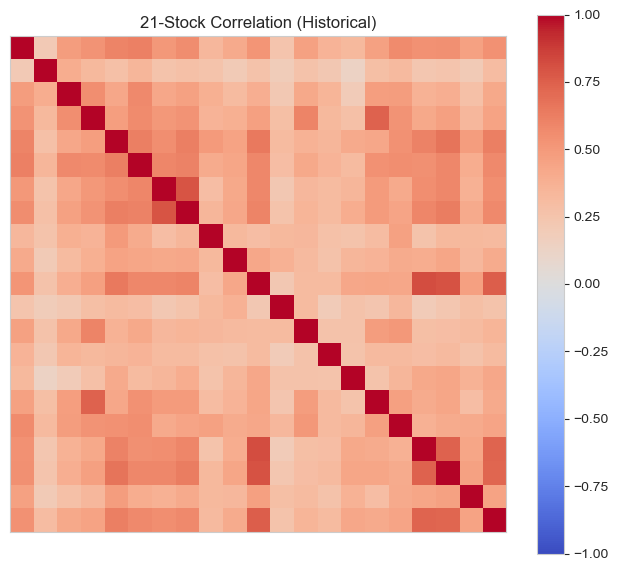

Mean correlation: 0.407


In [22]:
returns = pd.read_parquet(data_dir / 'processed' / 'returns.parquet')
corr_matrix = returns.corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_title('21-Stock Correlation (Historical)')
ax.set_xticks([])
ax.set_yticks([])
plt.colorbar(im)
plt.show()

#print mean cor
print(f"Mean correlation: {corr_matrix.values[np.triu_indices_from(corr_matrix.values, k=1)].mean():.3f}")

## Target distribution across splits

Regime shift evident: train centered ~-62bps, test drops to ~-87bps (crisis period Q4 2024-Q1 2025).

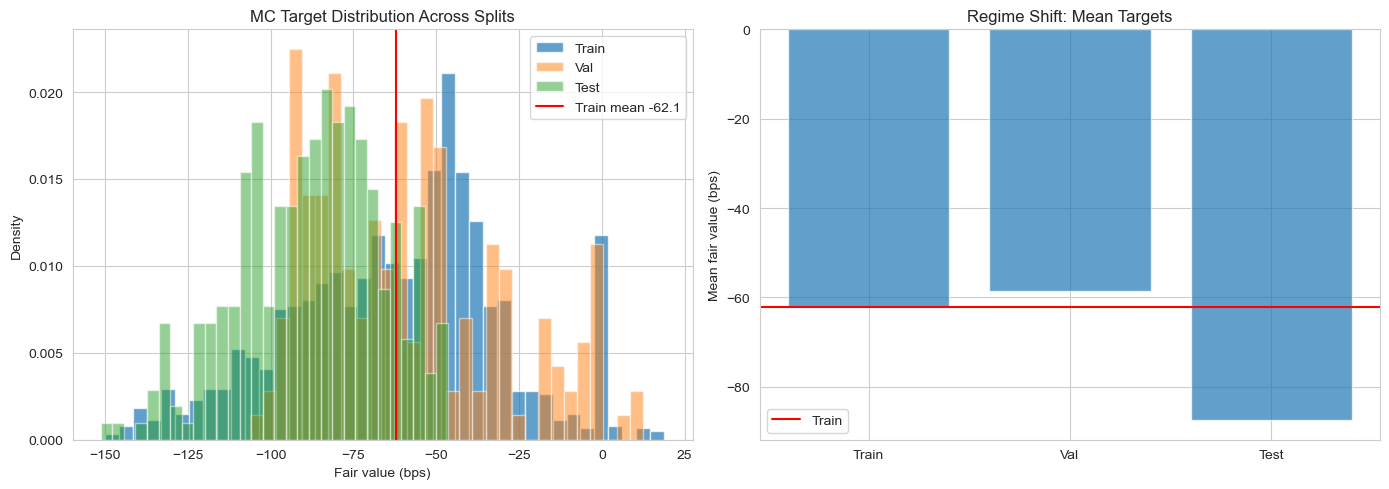

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(y_train, bins=40, alpha=0.7, label='Train', density=True)
axes[0].hist(y_val, bins=30, alpha=0.5, label='Val', density=True)
axes[0].hist(y_test, bins=30, alpha=0.5, label='Test', density=True)
axes[0].axvline(y_train.mean(), c='r', label=f'Train mean {y_train.mean():.1f}')
axes[0].set_xlabel('Fair value (bps)')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].set_title('MC Target Distribution Across Splits')

means = [y_train.mean(), y_val.mean(), y_test.mean()]
axes[1].bar(['Train', 'Val', 'Test'], means, alpha=0.7)
axes[1].axhline(y_train.mean(), c='r', label='Train')
axes[1].set_ylabel('Mean fair value (bps)')
axes[1].set_title('Regime Shift: Mean Targets')
axes[1].legend()
axes[1].grid(True, axis='y')

plt.tight_layout()
plt.show()

## Weights calibration

Monthly rebalanced EURO STOXX 50 weights used for dispersion payoff calculation.

In [23]:
weights = pd.read_csv(data_dir / 'sx5e_weights_monthly.csv', index_col=0, parse_dates=True)
print(weights.head())
print(f"\nWeight sum (all 1.0): {weights.sum(axis=1).mean():.4f}")
print(f"\nTop 5 mean weights:")
print(weights.mean().nlargest(5))

                 SAP   ASML.AS     MC.PA    ALV.DE    SIE.DE    BMW.DE  \
Date                                                                     
2018-01-31  0.042049  0.063540  0.093021  0.058050  0.036117  0.024952   
2018-02-28  0.040418  0.065419  0.094561  0.057059  0.034559  0.024537   
2018-03-31  0.040945  0.065388  0.096622  0.054862  0.033212  0.025080   
2018-04-30  0.039201  0.058930  0.102725  0.053387  0.030788  0.023899   
2018-05-31  0.039231  0.060664  0.102159  0.048372  0.031474  0.022330   

              MBG.DE    DB1.DE   BAYN.DE    BNP.PA    SAN.PA     OR.PA  \
Date                                                                     
2018-01-31  0.015534  0.037030  0.034401  0.017504  0.021706  0.068352   
2018-02-28  0.015467  0.040851  0.032712  0.017897  0.020675  0.068849   
2018-03-31  0.015239  0.041556  0.031411  0.016584  0.020909  0.071776   
2018-04-30  0.014031  0.038109  0.030863  0.016019  0.019128  0.072045   
2018-05-31  0.012797  0.038642  0.031

## Summary

Pipeline components generated via MC (50k paths):
- Targets: -62.1bps (train), regime shift to -87.5bps (test)
- Features: 274D from spots/forwards, rates, synthetic IV surfaces (+ padding)
- Correlation: Historical 21×21 structure preserved
- Weights: Monthly SX5E rebalanced composition

Foundation for NN learning (notebooks 1-5).